# LuSNAR → PyTorch DataLoaders (depth + segmentation)

Uses `lusnar_dataset.py` (keep it in the same folder as this notebook, or set `CODE_DIR`).

Each batch is a dict, ready for a DINOv3 backbone with a depth head and a segmentation head:

| key | shape | dtype | meaning |
| --- | --- | --- | --- |
| `image` | B×3×H×W | float32 | left RGB (`image0/color`), ImageNet-normalised |
| `depth` | B×1×H×W | float32 | depth from `image0/depth/*.pfm`, 0 where invalid |
| `depth_valid` | B×1×H×W | bool | mask for the depth loss (finite, > 0, ≤ `MAX_DEPTH`) |
| `label` | B×H×W | int64 | class 0–4, 255 = ignore |

**Split is by scene** (whole scenes go to train / val / test), so near-identical consecutive
frames never leak between splits.

Packages (in your environment): `pip install --no-cache-dir torch numpy pandas pillow matplotlib`.
For GPU training, install and run on a GPU node.

In [1]:
from pathlib import Path

ROOT = Path("/proj/uppmax2026-1-299/task1_groupc_dataset/lusnar/extracted")   # folder with Moon_1 … Moon_9
def _find_code_dir(name="lusnar_dataset.py"):
    """Folder containing lusnar_dataset.py: the notebook's folder (VS Code), else cwd or one of its parents."""
    cands = [Path(globals()["__vsc_ipynb_file__"]).parent] if "__vsc_ipynb_file__" in globals() else []
    cands += [Path.cwd(), *Path.cwd().parents]
    for d in cands:
        if (d / name).exists():
            return d
    raise FileNotFoundError(f"{name} not found in {[str(c) for c in cands[:3]]} ... - set CODE_DIR by hand")

UPPMAX_CODE_DIR = Path("/proj/uppmax2026-1-299/task1_groupc_dataset")   # copy of lusnar_dataset.py on UPPMAX
# On UPPMAX use that copy (re-scp it after editing the local file); locally, search next to the notebook.
CODE_DIR = UPPMAX_CODE_DIR if (UPPMAX_CODE_DIR / "lusnar_dataset.py").exists() else _find_code_dir()
print("CODE_DIR:", CODE_DIR)
IMAGE_SIZE = 512                    # multiple of 16 (DINOv3 patch size); 1024 = full resolution
BATCH_SIZE = 8
NUM_WORKERS = 8                     # ≈ number of cores you booked
MAX_DEPTH = None                    # e.g. 30.0 to ignore far pixels; check section 5 first
VAL_SCENES = ["Moon_8"]             # choose scenes; [] + [] = random pick (n_val=1, n_test=1)
TEST_SCENES = ["Moon_9"]
INDEX_CACHE = Path.home() / "lusnar_cache" / "index.csv"   # speeds up re-runs; delete to re-scan
SEED = 0
N_VAL, N_TEST = 1, 1                # only used when VAL_SCENES / TEST_SCENES are empty

# Local fallback: no cluster path -> use the Moon_1 scene extracted next to this notebook.
# With a single scene there is nothing to split, so everything goes to "train".
if not ROOT.exists() and (CODE_DIR / "Moon_1").exists():
    ROOT = CODE_DIR / "Moon_1"
    VAL_SCENES, TEST_SCENES, N_VAL, N_TEST = [], [], 0, 0
    INDEX_CACHE = None
    print("Cluster ROOT not found -> using local", ROOT)

CODE_DIR: /proj/uppmax2026-1-299/task1_groupc_dataset


In [2]:
import sys, time
sys.path.insert(0, str(CODE_DIR))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import lusnar_dataset as L     

torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.11.0+cu128 | device: cpu


## 1. Index the files (paths only) and look at the scenes

In [3]:
index = L.build_index(ROOT, cache=INDEX_CACHE)
index.groupby("scene").size().rename("frames").to_frame().T

Indexed 13,006 usable frames in 9 scenes (0 dropped for missing ['rgb', 'depth', 'label'])


scene,Moon_1,Moon_2,Moon_3,Moon_4,Moon_5,Moon_6,Moon_7,Moon_8,Moon_9
frames,1094,1597,1230,1320,1599,1102,1626,1351,2087


## 2. Build datasets and DataLoaders

In [4]:
cfg = L.LoaderConfig(
    root=str(ROOT), image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    max_depth=MAX_DEPTH, val_scenes=VAL_SCENES, test_scenes=TEST_SCENES,
    augment_train=True,               # random crop + horizontal flip + brightness/contrast (train only)
    n_val=N_VAL, n_test=N_TEST,
    index_cache=str(INDEX_CACHE) if INDEX_CACHE else None, seed=SEED,
)
loaders, datasets = L.make_dataloaders(cfg)
train_loader, val_loader = loaders["train"], loaders.get("val")
print({k: f"{len(v)} batches" for k, v in loaders.items()})

train:  9,568 frames | scenes ['Moon_1', 'Moon_2', 'Moon_3', 'Moon_4', 'Moon_5', 'Moon_6', 'Moon_7']
val  :  1,351 frames | scenes ['Moon_8']
test :  2,087 frames | scenes ['Moon_9']
{'train': '1196 batches', 'val': '169 batches', 'test': '261 batches'}


## 3. Inspect one batch

In [5]:
batch = next(iter(train_loader))
for k, v in batch.items():
    if torch.is_tensor(v):
        print(f"{k:12s} {str(tuple(v.shape)):20s} {str(v.dtype):15s} "
              f"min {v.float().min():8.3f}  max {v.float().max():8.3f}")
print("valid depth fraction:", batch["depth_valid"].float().mean().item())
print("label values present:", torch.unique(batch["label"]).tolist())

image        (8, 3, 512, 512)     torch.float32   min   -2.053  max    2.640
depth        (8, 1, 512, 512)     torch.float32   min    0.000  max 4320.000
depth_valid  (8, 1, 512, 512)     torch.bool      min    0.000  max    1.000
label        (8, 512, 512)        torch.int64     min    0.000  max    4.000
valid depth fraction: 0.7826790809631348
label values present: [0, 1, 2, 3, 4]


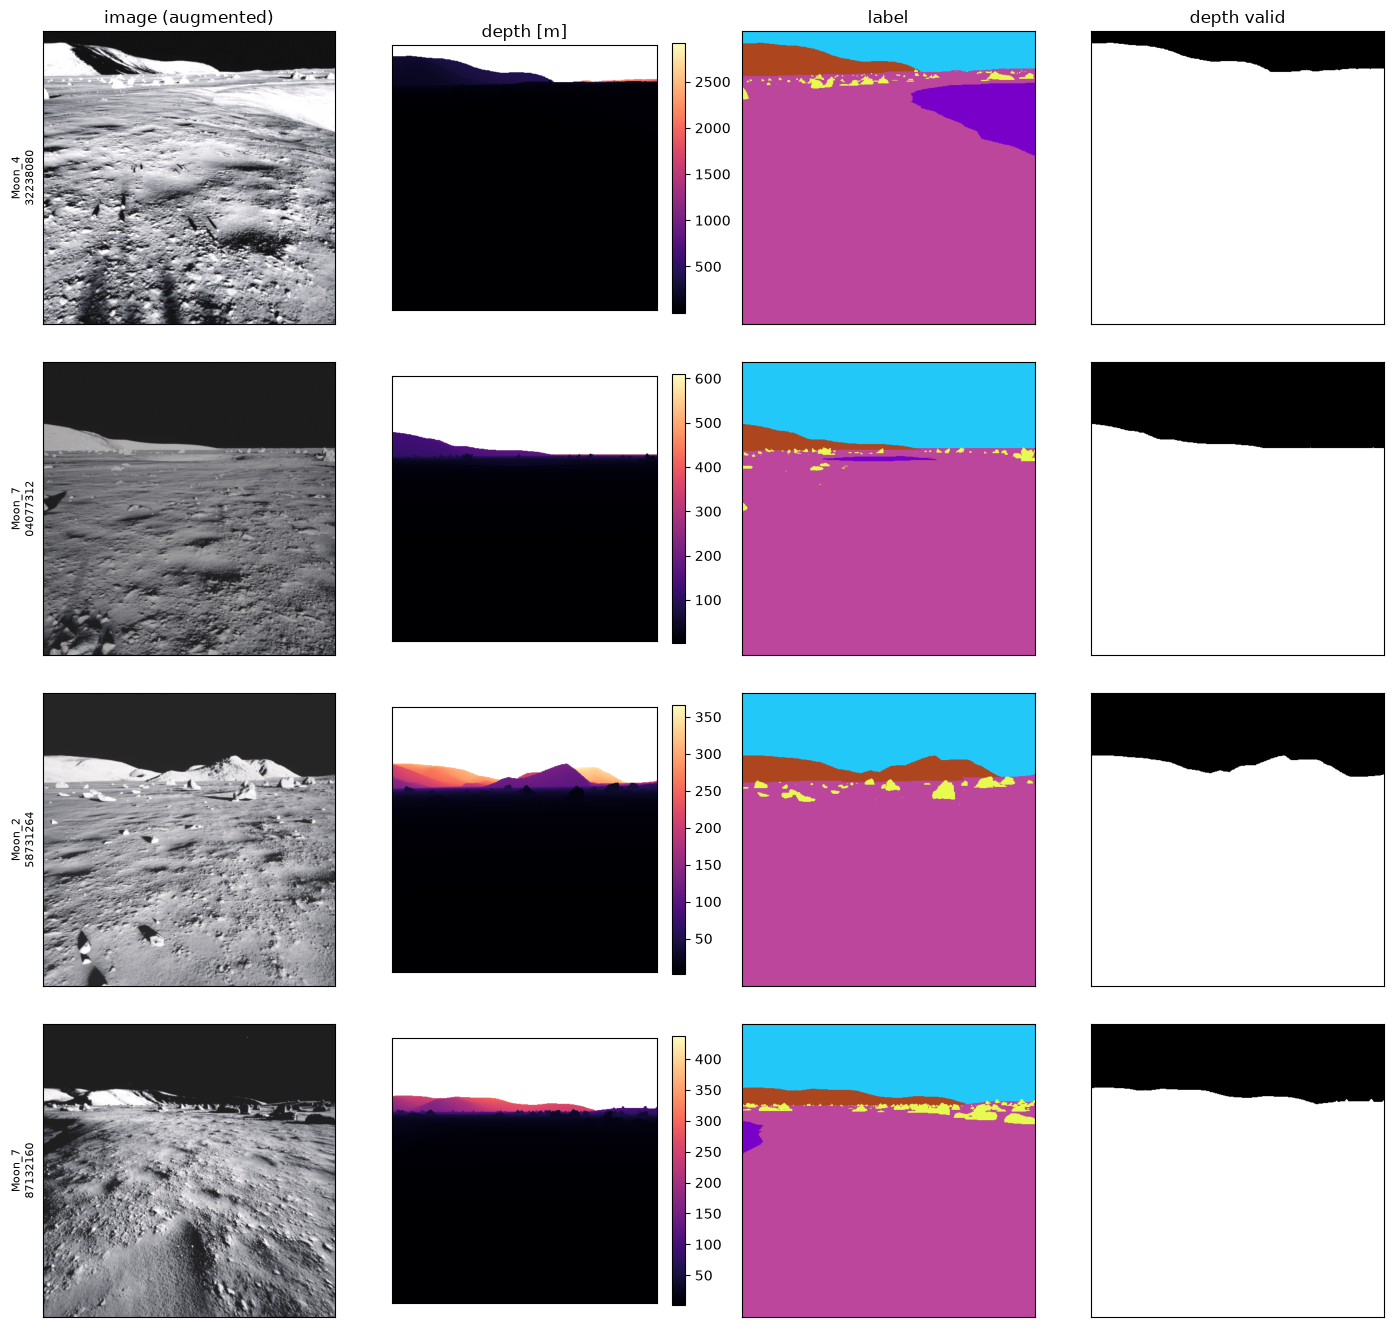

In [6]:
n = min(4, batch["image"].shape[0])
fig, ax = plt.subplots(n, 4, figsize=(14, 3.4 * n), squeeze=False)
for i in range(n):
    img = L.denormalize(batch["image"][i]).permute(1, 2, 0).numpy()
    dep = batch["depth"][i, 0].numpy().copy()
    dep[~batch["depth_valid"][i, 0].numpy()] = np.nan
    ax[i, 0].imshow(img)
    im = ax[i, 1].imshow(dep, cmap="magma"); plt.colorbar(im, ax=ax[i, 1], fraction=0.046)
    ax[i, 2].imshow(L.class_to_rgb(batch["label"][i].numpy()))
    ax[i, 3].imshow(batch["depth_valid"][i, 0].numpy(), cmap="gray")
    ax[i, 0].set_ylabel(f"{batch['scene'][i]}\n{batch['stem'][i][-8:]}", fontsize=8)
for a, t in zip(ax[0], ["image (augmented)", "depth [m]", "label", "depth valid"]):
    a.set_title(t)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 4. Class balance → weights for the segmentation loss

In [7]:
counts = L.class_pixel_counts(datasets["train"], n_samples=200)
weights = L.class_weights(counts)            # inverse sqrt frequency, mean 1
pd.DataFrame({"class": L.CLASS_NAMES, "pixel_share_%": (100 * counts / counts.sum()).round(2),
              "weight": weights.numpy().round(3)})

,class,pixel_share_%,weight
0,Lunar Regolith,68.61,0.244
1,Impact Crater,1.19,1.853
2,Rock,2.34,1.322
3,Mountain,2.95,1.177
4,Sky,24.92,0.405


## 5. Depth range (to choose `MAX_DEPTH`)

Sky pixels are stored as 65504 (float16 max) in the PFMs; they are excluded here and are `depth_valid = False` in the batches.

depth percentiles [m]: {1: 1.34, 50: 2.79, 90: 20.0, 99: 406.75, 99.9: 1588.0}


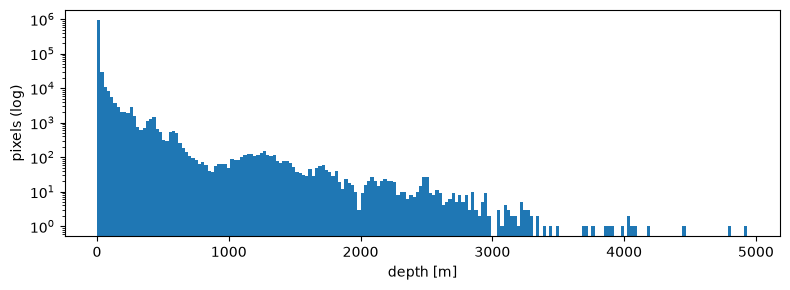

In [8]:
vals = []
for i in np.random.default_rng(SEED).choice(len(datasets["train"]), size=min(50, len(datasets["train"])), replace=False):
    d = L.load_depth(datasets["train"].idx.iloc[int(i)]["depth"])
    d = d[np.isfinite(d) & (d > 0) & (d < L.DEPTH_SKY_VALUE)]   # 65504 = sky, no depth
    vals.append(d[:: max(1, d.size // 20000)])
vals = np.concatenate(vals)
print("depth percentiles [m]:", {p: round(float(np.percentile(vals, p)), 2) for p in (1, 50, 90, 99, 99.9)})
plt.figure(figsize=(8, 3)); plt.hist(vals, bins=200, log=True)
plt.xlabel("depth [m]"); plt.ylabel("pixels (log)"); plt.tight_layout(); plt.show()

## 6. Loader speed
If this is much slower than your model's step time, raise `NUM_WORKERS` or lower `IMAGE_SIZE`.

In [9]:
n_batches = min(20, len(train_loader))
t0 = time.time()
for i, b in enumerate(train_loader):
    if i + 1 >= n_batches:
        break
dt = (time.time() - t0) / n_batches
print(f"{dt:.3f} s/batch  →  {BATCH_SIZE / dt:.1f} images/s")

0.321 s/batch  →  24.9 images/s


## 7. Using the batches in a training step
A tiny stand-in model shows how the batch keys plug into the two losses. Replace it with
your DINOv3 backbone + heads (sketch in the next cell).

In [10]:
import torch.nn as nn
import torch.nn.functional as F

class TinyStandIn(nn.Module):
    """Placeholder with the same inputs/outputs as a DINOv3 depth+seg model."""
    def __init__(self, n_classes=L.NUM_CLASSES):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 3, stride=4, padding=1), nn.ReLU())
        self.depth_head = nn.Conv2d(16, 1, 1)
        self.seg_head = nn.Conv2d(16, n_classes, 1)
    def forward(self, x):
        f = self.enc(x)
        depth = F.softplus(self.depth_head(f))           # positive depth
        seg = self.seg_head(f)
        size = x.shape[-2:]
        return (F.interpolate(depth, size, mode="bilinear", align_corners=False),
                F.interpolate(seg, size, mode="bilinear", align_corners=False))

model = TinyStandIn().to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
seg_loss_fn = nn.CrossEntropyLoss(weight=weights.to(DEVICE), ignore_index=L.IGNORE_INDEX)
W_DEPTH, W_SEG = 1.0, 1.0

model.train()
for step, b in enumerate(train_loader):
    x = b["image"].to(DEVICE, non_blocking=True)
    depth, valid = b["depth"].to(DEVICE), b["depth_valid"].to(DEVICE)
    label = b["label"].to(DEVICE)

    pred_depth, pred_seg = model(x)
    loss_d = L.silog_loss(pred_depth, depth, valid)      # or L.masked_depth_l1(...)
    loss_s = seg_loss_fn(pred_seg, label)
    loss = W_DEPTH * loss_d + W_SEG * loss_s

    opt.zero_grad(); loss.backward(); opt.step()
    print(f"step {step}: depth {loss_d.item():.3f}  seg {loss_s.item():.3f}")
    if step == 2:
        break

step 0: depth 1.520  seg 1.563
step 1: depth 1.674  seg 1.617
step 2: depth 1.515  seg 1.565


## 8. DINOv3 ViT-S/16 + a very simple depth head (inference)
Smallest DINOv3 on Hugging Face: **`facebook/dinov3-vits16-pretrain-lvd1689m`** (ViT-S/16, ~21.6M params,
ImageNet normalisation, so it matches the loader).

The weights are **gated**: accept the licence on the model page, then `huggingface-cli login` (on the
cluster, download on a login node first). If loading fails, the cell falls back to **random weights** with the
same architecture, so the rest of the section still runs but only tests the plumbing.

Token layout: `[CLS, 4 registers, h·w patch tokens]`, with h = H/16 and w = W/16 (512×512 → 32×32 grid).

In [11]:
from transformers import AutoModel, DINOv3ViTConfig, DINOv3ViTModel

DINO_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"

try:
    backbone = AutoModel.from_pretrained(DINO_ID)
    PRETRAINED = True
    print("Loaded pretrained", DINO_ID)
except OSError as e:          # gated repo without access, no internet, ...
    PRETRAINED = False
    print(f"!! Could not load {DINO_ID}: {str(e).splitlines()[0]}\n"
          "!! Using RANDOM weights with the ViT-S/16 architecture - shapes/plumbing only.")
    backbone = DINOv3ViTModel(DINOv3ViTConfig(num_register_tokens=4))   # defaults = ViT-S/16

backbone = backbone.to(DEVICE).eval().requires_grad_(False)   # frozen backbone
PATCH = backbone.config.patch_size
N_PREFIX = 1 + backbone.config.num_register_tokens            # CLS + register tokens
print(f"{sum(p.numel() for p in backbone.parameters()) / 1e6:.1f}M params | "
      f"dim {backbone.config.hidden_size} | patch {PATCH} | prefix tokens {N_PREFIX}")

/gorilla/proj/uppmax2026-1-299/task1_groupc_dataset/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


!! Could not load facebook/dinov3-vits16-pretrain-lvd1689m: You are trying to access a gated repo.
!! Using RANDOM weights with the ViT-S/16 architecture - shapes/plumbing only.
21.6M params | dim 384 | patch 16 | prefix tokens 5


In [13]:
class SimpleDepthHead(nn.Module):
    """Patch features [B, C, h, w] -> conv3x3 -> ReLU -> conv1x1 -> positive depth, upsampled to H x W."""
    def __init__(self, in_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.BatchNorm2d(in_dim),
            nn.Conv2d(in_dim, hidden, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(hidden, 1, 1),
        )

    def forward(self, feat, out_size):
        d = F.softplus(self.net(feat))          # > 0, as silog_loss expects
        return F.interpolate(d, out_size, mode="bilinear", align_corners=False)


class DinoDepth(nn.Module):
    def __init__(self, backbone, n_prefix, patch):
        super().__init__()
        self.backbone, self.n_prefix, self.patch = backbone, n_prefix, patch
        self.head = SimpleDepthHead(backbone.config.hidden_size)

    def features(self, x):
        B, _, H, W = x.shape
        h, w = H // self.patch, W // self.patch
        tokens = self.backbone(pixel_values=x).last_hidden_state   # [B, n_prefix + h*w, C]
        patch = tokens[:, self.n_prefix:]
        assert patch.shape[1] == h * w, (patch.shape, h, w)
        return patch.transpose(1, 2).reshape(B, -1, h, w)          # [B, C, h, w]

    def forward(self, x):
        return self.head(self.features(x), x.shape[-2:])


depth_model = DinoDepth(backbone, N_PREFIX, PATCH).to(DEVICE).eval()
print(f"head params: {sum(p.numel() for p in depth_model.head.parameters()):,}")

head params: 443,393


In [14]:
# A few un-augmented frames (val split if there is one, otherwise train)
split = "val" if "val" in datasets else "train"
infer_ds = L.LuSNARDataset(datasets[split].idx, image_size=IMAGE_SIZE, max_depth=MAX_DEPTH, augment=False)
ids = np.linspace(0, len(infer_ds) - 1, 4).astype(int)
samples = [infer_ds[int(i)] for i in ids]
x = torch.stack([s["image"] for s in samples]).to(DEVICE)
gt = torch.stack([s["depth"] for s in samples]).to(DEVICE)
valid = torch.stack([s["depth_valid"] for s in samples]).to(DEVICE)

with torch.inference_mode():
    t0 = time.time()
    feat = depth_model.features(x)
    pred = depth_model.head(feat, x.shape[-2:])
    dt = time.time() - t0
print(f"{split}: input {tuple(x.shape)} -> features {tuple(feat.shape)} -> depth {tuple(pred.shape)} "
      f"| {dt:.2f} s on {DEVICE}")


def depth_metrics(pred, gt, valid):
    p, g = pred[valid], gt[valid]
    ratio = torch.maximum(p / g, g / p)
    return {"AbsRel": ((p - g).abs() / g).mean().item(),
            "RMSE_m": ((p - g) ** 2).mean().sqrt().item(),
            "d<1.25": (ratio < 1.25).float().mean().item()}

# The head is untrained, so its scale is arbitrary: also report after per-image median scaling.
scale = torch.stack([gt[i][valid[i]].median() / pred[i][valid[i]].median() for i in range(len(x))]).view(-1, 1, 1, 1)
print("raw          :", {k: round(v, 3) for k, v in depth_metrics(pred, gt, valid).items()})
print("median-scaled:", {k: round(v, 3) for k, v in depth_metrics(pred * scale, gt, valid).items()})
print("silog loss   :", round(L.silog_loss(pred, gt, valid).item(), 3))

val: input (4, 3, 512, 512) -> features (4, 384, 32, 32) -> depth (4, 1, 512, 512) | 0.80 s on cpu
raw          : {'AbsRel': 0.766, 'RMSE_m': 84.479, 'd<1.25': 0.0}
median-scaled: {'AbsRel': 0.576, 'RMSE_m': 83.911, 'd<1.25': 0.191}
silog loss   : 1.56


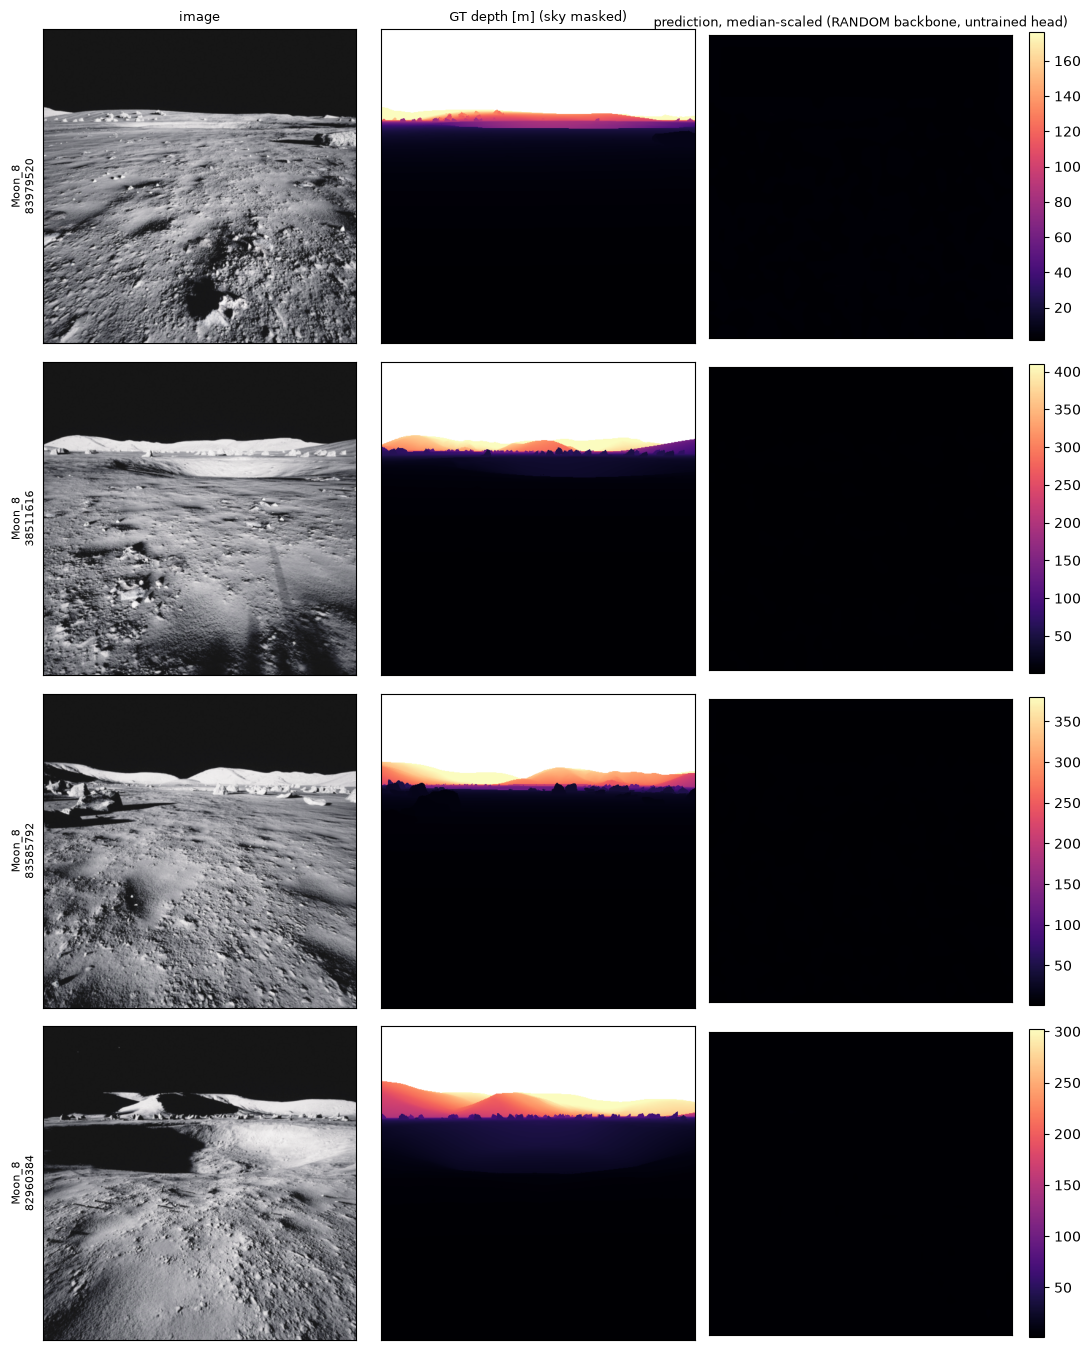

In [15]:
n = len(samples)
fig, ax = plt.subplots(n, 3, figsize=(11, 3.4 * n), squeeze=False)
for i in range(n):
    g = gt[i, 0].cpu().numpy().copy(); g[~valid[i, 0].cpu().numpy()] = np.nan
    p = (pred[i, 0] * scale[i, 0]).cpu().numpy()
    vmin, vmax = np.nanpercentile(g, [1, 99])
    ax[i, 0].imshow(L.denormalize(x[i].cpu()).permute(1, 2, 0).numpy())
    ax[i, 1].imshow(g, cmap="magma", vmin=vmin, vmax=vmax)
    im = ax[i, 2].imshow(p, cmap="magma", vmin=vmin, vmax=vmax); plt.colorbar(im, ax=ax[i, 2], fraction=0.046)
    ax[i, 0].set_ylabel(f"{samples[i]['scene']}\n{samples[i]['stem'][-8:]}", fontsize=8)
for a, t in zip(ax[0], ["image", "GT depth [m] (sky masked)",
                        f"prediction, median-scaled ({'pretrained' if PRETRAINED else 'RANDOM'} backbone, untrained head)"]):
    a.set_title(t, fontsize=9)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The head is untrained, so the prediction is not meaningful yet. To train it, reuse the loop from section 7
with `depth_model` (only `depth_model.head.parameters()` in the optimiser while the backbone is frozen) and
`L.silog_loss(pred, b["depth"], b["depth_valid"])`.